LangChain


In [120]:
from langchain_core.messages import SystemMessage,HumanMessage
from dotenv import load_dotenv
from langchain_groq import ChatGroq
import os


load_dotenv()

True

In [121]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0.3
)

In [122]:
from langchain_core.messages import SystemMessage

def chat_llm(messages, system_message = "You are a helpful assistant"):

    system_message = SystemMessage(system_message)
    all_message = [system_message] + messages
    response = llm.invoke(all_message)

    return response.content

LangGraph

In [123]:
import sqlite3
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.sqlite import SqliteSaver
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage,base
from llm import chat_llm

In [124]:
class ChatState(MessagesState):
    mode : str
    sources : list[str]


# class ChatState(TypedDict):
#     messages: Annotated[list[AnyMessage], add_messages]
#     mode: str
#     sources: list[str]

In [125]:
def chat_node(state : ChatState):
    messages = state['messages']
    response = chat_llm(messages)

    return {
        'messages' : [AIMessage(content=response)],
        "sources": []
        }

In [126]:
conn = sqlite3.connect("Test_database/chat_history.db", check_same_thread=False)
checkpointer = SqliteSaver(conn)

In [127]:
graph_builder = StateGraph(ChatState)

graph_builder.add_node("chat_node",chat_node)
graph_builder.add_node('rag_node',rag_node)

graph_builder.add_conditional_edges(START,router,{"chat": "chat_node",
        "rag": "rag_node"})
graph_builder.add_edge("rag_node", END)
graph_builder.add_edge("chat_node", END)


chatbot = graph_builder.compile(checkpointer=checkpointer)

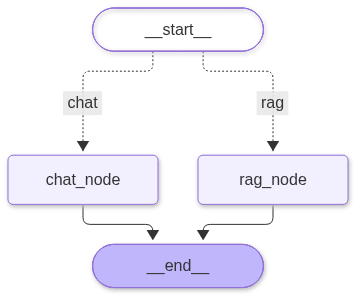

In [128]:
chatbot

RAG

In [129]:
from langchain_community.document_loaders import PyPDFLoader,TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import FAISS
from dotenv import load_dotenv
load_dotenv()


True

In [130]:
embeddings = GoogleGenerativeAIEmbeddings(model = "gemini-embedding-001")

In [131]:
FAISS_PATH = "faiss_index"
store = None

In [132]:
#understand this code what's it's purpos 
def get_store():

    global store
    if store is None:
        return store

    if os.path.exists(FAISS_PATH):
        store = FAISS.load_local(
            FAISS_PATH,
            embeddings,
            allow_dangerous_deserialization=True
        )
        return store

    return None

In [133]:
#understand this code what's it's purpos 
def load_file(file_path): 
    if file_path.endswith('.pdf'):
        loader = PyPDFLoader(file_path)

    else:
        loader = TextLoader(
            file_path,
            encoding = 'utf-8'
        )

    return loader.load()

In [134]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=400,
    chunk_overlap=50
)

In [135]:
def ingest_file(file_path):
    global store

    documents = load_file(file_path)

    for doc in documents:
        doc.metadata['source'] = os.path.basename(file_path)

        chunks = text_splitter.split_documents(documents)

        if store is None:
            store = FAISS.from_documents(chunks, embeddings)

        else:
            store.add_documents(chunks)

        store.save_local(FAISS_PATH)

        return len(chunks)

In [136]:
if __name__ == "__main__":

    chunks_count = ingest_file("test.txt")

    print(f"Total chunks created: {chunks_count}")

Total chunks created: 1


In [137]:
def retrieve(question,k=4):
    vectore_store = get_store()

    if vectore_store is None:
        return []

    results = vectore_store.similarity_search(
        question,
        k=4
    )
    return results

Graph.py


In [138]:
from rag import retrieve

In [139]:
def rag_node(state: ChatState):


    question = state["messages"][-1].content


    docs = retrieve(question)


    if not docs:
        return {
            "messages": [
                AIMessage(content="No documents found. Please upload a file first.")
            ],
            "sources": []
        }

    
    context = "\n\n".join(
        f"Source: {doc.metadata.get('source', 'Unknown')}\n{doc.page_content}"
        for doc in docs
    )

  
    system_message = (
        "Answer using only the provided context. "
        "If the answer is not available in the context, say 'I don't know'.\n\n"
        f"Context:\n{context}"
    )


    response = chat_llm(
        state["messages"],
        system_message=system_message
    )

    
    sources = list({
        doc.metadata.get("source", "Unknown")
        for doc in docs
    })

    return {
        "messages": [AIMessage(content=response)],
        "sources": sources
    }

In [140]:
def router(state: ChatState):
    if state['mode'] == 'rag':
        return "rag"

    return "chat"

In [141]:
if __name__ == "__main__":

    # Test Normal Chat
    response = chatbot.invoke(
        {
            "messages": [HumanMessage(content="Hello")],
            "mode": "normal"
        },
        config={"configurable": {"thread_id": "test1"}}
    )

    print("Normal Chat:", response["messages"][-1].content)
    print("Sources:", response["sources"])

    # Test RAG Chat
    response = chatbot.invoke(
        {
            "messages": [
                HumanMessage(content="What is this document about?")
            ],
            "mode": "rag"
        },
        config={"configurable": {"thread_id": "test2"}}
    )

    print("RAG Chat:", response["messages"][-1].content)
    print("Sources:", response["sources"])

Normal Chat: Hi there! How can I help you today?
Sources: []
RAG Chat: No documents found. Please upload a file first.
Sources: []


In [142]:
import streamlit as st 
import os 
import uuid

from langchain_core.messages import HumanMessage

from graph import chatbot
from rag import ingest_file


st.set_page_config(
    page_title="Multipurpse Chatbot",
    layout="wide"
)

if 'session_id' not in st.session_state:
    st.session_state.session_id = str(uuid.uuid4)

if 'messages' not in st.session_state:
    st.session_state.messages = []

2026-11-18 04:34:09.441 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.443 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.445 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.446 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.447 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [143]:
def ask(question, mode):

    # Create LangGraph configuration
    config = {
        "configurable": {
            "thread_id": st.session_state.session_id
        }
    }

    # Send user message to LangGraph
    response = chatbot.invoke(
        {
            "messages": [HumanMessage(content=question)],
            "mode": mode
        },
        config=config
    )

    answer = response['messages'[-1].content]

    sources = response.get("sources",[])

    return answer,sources



In [144]:
def upload_file(uploaded_file):
    os.makedirs("Uploads",exist_ok=True)

    file_path = os.path.join("Uploads",uploaded_file.name)

    with open(file_path,"wb") as file:
        file.write(uploaded_file.getbuffer())

    chunks = ingest_file(file_path)

    return chunks

In [145]:
def clear_chat():
    st.session_state.session_id = str(uuid.uuid4())
    st.session_state.messages = []

In [146]:
with st.sidebar:

    st.title("Multipurpose Chatbot")
    selected_mode = st.radio(
        'Selected Chat Mode',
        ['Normal Chat','RAG']
    )

    mode = "normal" if selected_mode == 'Normal Chat' else "rag"

2026-11-18 04:34:09.516 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.517 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.518 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.519 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.520 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.521 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.522 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.524 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [147]:
upload_file = st.file_uploader(
    "upload your document",
    type= ["pdf","txt"]
)


2026-11-18 04:34:09.545 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.546 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.547 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.548 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.549 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [148]:
if st.button("upload"):
    if upload_file is not None:
        with st.spinner("Loading..."):
            chunks = upload_file(upload_file)
        st.success(f"successfull upload !{chunks}")
    else:
        st.warning("Pls select a Document First")

2026-11-18 04:34:09.570 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.571 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.572 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.575 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.576 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [149]:
if st.button("Clear Chat"):
    clear_chat()
    st.rerun()

2026-11-18 04:34:09.591 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.592 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.593 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.595 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:34:09.596 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [150]:
for message in st.session_state.messages:
    with st.chat_message(message['role']):
        st.write(message["content"])

    if message.get("Sources"):
        st.caption(
            "Sources: " + ", ".join(message["sources"])
        )

2026-11-18 04:34:09.614 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [151]:
user_input = st.chat_input("Enter you message here ")

if user_input:
    st.session_state.mssages.append({
        'role' : "user",
        'content' : user_input
    })

    with st.chat_message('user'):
        st.write(user_input)

    with st.chat_message("assistent"):
        with st.spinner("Answering..."):
            answer,sources = ask(user_input,mode)
        st.write(answer)

        if sources:
            st.caption("Sources: " + ", ".join(sources))

        st.session_state.messages.append({
            "role" : 'assistant',
            'content': answer,
            'sources': sources
        })

2026-11-18 04:39:55.075 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:39:55.077 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:39:55.078 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:39:55.079 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 04:39:55.080 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [152]:
try:
    with st.chat_message('assistent'):
        with st.spinner('thinking'):
            answer,sources = ask(user_input,mode)
        st.write(answer)

        if sources:
            st.caption("Sources: " + ", ".join(sources))

        st.session_state.messages.append({
            "role": "assistant",
            "content": answer,
            "sources": sources
        })

except Exception as e:
    st.error(f"Something went wrong: {e}")

2026-11-18 05:00:44.983 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 05:00:44.985 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 05:00:44.986 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 05:00:44.987 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 05:00:44.992 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 05:00:44.994 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 05:00:44.996 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [ ]:
if mode == "rag" and not os.path.exists('faiss_index'):
    st.warning("pls upload the file ")